# Population Size and History from Present-Day DNA

Can DNA sampled today distinguish a founder event from recent growth?
We generate one population with mutation, recombination and changing size.
The simulator records each generation. Estimators receive the final DNA,
an external mutation rate and a genetic map.

Diversity and LD give constant-size summaries. We compare specified
demographic histories and check their predictions on reserved chromosomes.
The simulation uses small population sizes and elevated rates so that its
probability model can be inspected directly. Install hpgR before running.


In [1]:
library(hpgR)
options(repr.plot.width = 9, repr.plot.height = 3.8,
        repr.plot.pointsize = 13, repr.plot.bg = "white", warn = 1)
blue <- "#265991"
orange <- "#D65F22"
gray <- "#777777"
truth_color <- "#B33B32"
model_colors <- c("#6D7884", "#3F8C83", orange, "#8B65A0")

drawFigure <- function(name, draw, width = 9, height = 3.8, pointsize = 13) {
    options(repr.plot.width = width, repr.plot.height = height,
            repr.plot.pointsize = pointsize)
    directory <- Sys.getenv("P8149_FIGURE_DIR")
    if (nzchar(directory)) {
        dir.create(directory, recursive = TRUE, showWarnings = FALSE)
        pdf(file.path(directory, paste0(name, ".pdf")), width = width,
            height = height, family = "Helvetica", pointsize = pointsize,
            useDingbats = FALSE, bg = "white")
        tryCatch(draw(), finally = dev.off())
    }
    if ("IRkernel" %in% loadedNamespaces()) draw()
    invisible(NULL)
}


## The final sample and its calibration

The embedded data contain **64 diploid people**, represented by **128 haploid
sequences**, across **eight chromosomes of 2,000 sites each**. Every site,
including invariant sites, is retained. Consecutive haplotype rows are the
two homologs of one person. Alleles are coded 0 and 1.

Each chromosome spans 0.2 Morgans. The mutation probability is
$u=v=2.5\times10^{-5}$ per site per generation for both 0-to-1 and 1-to-0
changes. Recurrent and reverse mutation are possible, so the frequency
spectrum uses **minor allele counts**. Allele 1 is simply a sequence state.

`observed` contains the final DNA. `calibration` contains the mutation rate
and map. `prediction_data` contains independent R simulation predictions
for candidate histories. It contains no generation records from the observed sample.


In [2]:
observed <- (function() {
  encoded <- c(
    "..."
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()

calibration <- (function() {
  encoded <- c(
    "...",
    "+Qmeefx/ADdeG80n3gUA"
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()

prediction_data <- (function() {
  encoded <- c(
    "H4sIAAAAAAAAA9V8BVhUW/sviKBiYqAiKha2woCAGD8VA7s7yAFG6QERRQwUQWqahhkaLDCwE7u7C+zAOHbBXTPutfFw3Pfe73m+",
    "+78enufHnv2ufNde66219p6hr6WlpaNVU1dHS0eX/NTSnTpleE8bLa0aTciNHnNtSFCfQJvA9ZffTTl+d6n6rfP0F3rtqt+1zpNr",
    "A/XvgV+tyl4Y2/Wk9ziRqP5L+qXcoN/Vp92ny2umTE2k7Zj4YnWbHShS/5/4EvuY+6q6XhHU0NRRU6uOupyLj5evk0uAg8A7QMj3",
    "q5Za09lJyGdotBfqawXTos6gFlqaP7z5+5XJw7SmXfnzWqPyf1sXU3CQ8e/qqvlrv3S9nbz4QvKjkeaxMKw4ebvwhQH+Tp4OQsFi",
    "PkOt5+YT6O3K9/+VZujsExDgyffmuyxwcCcXf6cAgY+3kEltxl/k6+QtJJTfJNbz9ecL+d4Bv1ZX18XD38fLR+ij7tNPUlOhIIAv",
    "dPAl7VYlMmn1vQIDNHU6kKopsZm6qQCBiwPplnuAh4OXj7+7kzeT2FDo5OXryXdwFfh6+ghcaSONnQP9vQW/62UjH2ch33/hz1aE",
    "fL4rLeHpSioRBqhHysHZn++0gJZo4iYICBB4uzv8hhcXDzJQ1dM0D0WzLGpWXTUP8/+0RLr8fJg6lczzq8m0U4t5UvQZC72cPD2Z",
    "m9qugT85ZO713P19ggI8/t6L3y28v/3+n+0Fl1j483ox4b/di9/W1qBqXfl4ewbTqSr0IJX6BDlo2iKzjM55f76Lep1VIzfw8VQv",
    "Zpb6k+m/NTOMNmPySzNtLc1MGG6EPUyszEx+WTQmTu4+NBvv/yqbyd+ymZv9M9//+BD8uhLVCkstUu2hOnkgrLF3ApRWqTqC89ZQ",
    "xlRkBIcdREa9kbvm9QFUc8NDBp7tBtWIjU0Xl9oj423+tyeeUchs7B0fM/4eMi00f8iYsb9T1F8zofxmkz+2Yy9krPL50OR0G+S1",
    "Grdi69NWyDm+te+MRs7Iu/zjXfGwDOQ6pTfcslaO7ENxc7p8KEFuZpfhlRMHIN9wTfca9UYhV93ciI3I6Xint1H6PmhatVMgt1nX",
    "rNVnQpC7U2tjycC2WHVxyOO9x3Wxen3xe37t+1iVI2ne59UgrOqwLC/N8Q3W6A/wzbymj7CAPfNDv9xC+OzFPNI1hJ1uUyd2g1vV",
    "tfWsUz7DJ/6jfHK3bnMT5NORXtlharePI6C89NrUuv4tJL0Mmi2O5SE5OP3iZydrpO62jG6QWQspjUVtGj31Q7Jge5lHZQxU19cG",
    "rtA6iLQOjyva6lgjvYVpeWXSEaTnfy6W2ptAfuPBkKEPJiL+QunJoXbzoBgwbExwh8eQrRV4vk1bCJGdc4nttoeQe/TYZ2q8DNJe",
    "jk8i899D+nDAlIf5zyDtEr3xgZkY0hlXNocPfg9Zlip6kMkGJLxMmNLcayVE/oMO2kfPhKTbsOWl7+ojetmeBm7tjCH6XHStsVcc",
    "RPPqP3gzsguks9YfDbu/GrK3YoHr5cYQf72vu75nPmQ9Lzfs5nIfcodDzXpe9YfIdLiDT3FDKLZk9V62cnY1tavjKvBixIaaXO/n",
    "VPtbltokC1XOTZh8Fcwq0KMKUOgmJPrT292TH8DKDwM1UbMI/Pl+gXxvF7o69NUJxErxYrPWJFrM/JffvF9+WzDL4ef0Tw8pF3v4",
    "F0J5ODn7weTPUDF2UWbxMPXKYKc5O+3lK/TIjER6P9dZxutrI+P8I8fBkdbIZKYXvVeZPlt0+cd7djrnaWb/OOS4af6Q+zp1c88G",
    "09jlkKcxwyZhXXtNBey0p/lyaraQkiZQQBo1N33GLic6vSPUqaFfsWzfQnUKVqmrVZ3CGtJ50lXE9oGaU/Z+qbrWmi2xhHD96ewN",
    "hKu7OXIXe/XXsN0PyV6HXuWOa4OUF9n8cZMMEN/63NR64XpIXTqnRf13EUiLqhjhV0TEh4dgSNSMa0i9f3bDqM+LoGzYu07v9z5I",
    "3Tw8xGCbGAlHcyIH5o6DShDzvW09FdKtPcIL+naHrE1sxe1BLSG5PiQyMeIWxMHH+7y/p4vEQ3HINd4JhUeD5etudYbsSmKPVrb5",
    "kC7Ms7I8NAPxun6xeatmQdp4pVans2EQr7+6LVo3ANHa51+t/vQB8nUDHHv2v4DovQcL++bsgmhZVPj4lgaI9uhff8NUK4jXVMya",
    "eb4MIvfd07wNrCF69KV5p2IVZO3fHOsxZgdZZjePBBXvgcRz0LTQe3Uh1g/qaZEzH2vT3tT/6GUIWVDNE7e2O/2c2zUrfz/ndSv/",
    "gDlOnsUiU9ttCjKH1YJyoRGUYepJPQEqtQSWXYSq1Y+h72qtRIa2RtYjw2XdTK+nJ5GhlszkOagirUcfzX0D1aQk+znXdrKqIFPp",
    "Zat3ScmK/owjX3o4SI4ikxGlbL2aYtrIrLWS1OzNqpyM74reJ5x/sCoiT93NuzHId1YnuCB32uZbF2Qd2Pu851fVwhv5dZM+mTS7",
    "jtwbR0YJ2gmRw8zZbHXzR74g797zzgn9myCHEfUFJNO8hzpVa7GR89iLbwuQp+72jP3IX6RehMORSwqRrrMqSa3HFtxejtVqjbNE",
    "xK6NKNIpohwQNlLdEUNEMPVQVULzr9RopoWsSlk9VfPH3kdomvNh6WFkIZIusmuU3q++7l7ysiwbkRp2Hdh0qspS2tV3uCtUIfno",
    "DfNaju2Q1D90YsXeMqQ6vvBc1Lw70no7pw6ZOhMq7ZA78vHhSKswjngT3h0Zo2W9ZZOPId3NYvjeV8uR2uSky7AjWkjPSiyIytVF",
    "6tpSu2dmXZF+0ibrY950ZAQ41mudMwtpRrqbjoaMQ9rTboWhejeQdm34jZ51WiHtiPvATXkKpG9wXjDm0gmkrGne7lqiAWTjvdNT",
    "XbsgwalfI5PPUZBOMp10+XUppGml0jMzVJCE/2g968kFxBu4b5aXBED2pXFo/vYsSNdrP4qJd4L4g2Xy/ZIHkD1ddNAsyQLxhmUl",
    "ecO2Il45fZpfgy+IP3Hi/d03/SAtG77kRuIDyAOedjmkfxOyRDNIBldCiojyY35iJApX31vV4ACkolFHTvVaD8loryYhzu0hjevU",
    "u8+zbpDLT6wo3T0PslsnCiYXzYb0jPUNBztriC/NKnl7zBWSZjViDzydB7m0TOqwVYC49Lc7jAK+QxxmMeNk1gskPnsXOnbNEMiO",
    "xZa2iWsNuVVK1PYOe0j5RlZ7HmlBvnOzWy3ZachD/JL7ReQi9t05W35FIiQey/xmPnGCdJrJ9Te7nKBYu6addsUHSE1vxtbf0+A3",
    "MqbpHydjqL5UadTkUFY/KtVLLf87lIPVQiSP1a+sbFFrUyMllCZqBTwFGYWaH8jWqCshK6sy1OqqhRTZau06+hiUGjU7htXfrIxi",
    "rjSd9itXs3TnIc9f3UAOq3dzfipYFBzQNISCUo1wq9LT1Axl1j7Vx/kz1ELkL9YsZdOZdig9S1266RJWf6/XdLcdCuZpFDJbjpUt",
    "jD6ma39xukahYyWjjyk9Rm0dLDyBFR5qhlKwkrFP4phxFzHjGcvEdyIZ2VddttB2qd2wnBm3aI2ZEczWm/Joz/UvHseQsbP4Zuse",
    "Pkg/NTXn04eBSK18eOT7R0dkTYgytdtWA8m+t9aOf+kIZW/58VR/EVKHOdoVfv2CpNHl6Z5t9JC8uNPURyYVSPOxvXH0+F5kjnux",
    "9+F7F2RYN/+sL7RE0qjeftmrQpDRJeLEpDgzomNK7ha/6o+U+S+SB9vURVrNVns2Fkig2rx5WsmoDCTPvXu1szgJCUYZJu1jHkK2",
    "+9WXQae1IX+t9+h1vx9Q3NK2rTAia6vh3mvzuiogLpSeOe1cC/Kupfm7mtlBofvX8MEbTiIh09R/dTQxr5sdPNVSGoP47KRvbi3e",
    "Q5Uqjy/b2QCJQ8ZO/VajN8QdvtS2NdSHSOuJz+A7iyH7sXlazsTJkHesHVHH5AokibcbrEp6hfgOg4pvrZoCiftG4fuiMihM9ez2",
    "mOxDfHOFc1BWO0idd/Dqtn4H0bH5wfbu5RBpWxk6OkyBWG5q2K5GPcSemi6o2C5FwtLRMYcDHCE/OdPs/qq5iHnzSOvZzq6QugRY",
    "PnbXReSYryaDinpC4TflWythB8R2vGQ/cfJeRLQ7bd10IiDRXzdg0rf7kEb1iG+5oyZkntZvKhfKkLzurd20C/lIqpnu59Vsyp8t",
    "YzR9qqelvTaSYC1BFEE0QQxBLEEcgYhATCAhkBLImHJNtXQMuhJ0I+hO0IOgJ0Evgt4EZgTmBDwCCwJLgj4EVgTWBDYEfQlsCfoR",
    "9K/mudNxqBPg7yTwdnATBNCg30+CJjZGwyUuTp6/5Kijvv01vYGmiDqQpg7J0fCaAckmcPavitX9Glur8uTT2roT3zgcqSlTiIFh",
    "xYrONM3KboS0aI1Bxl6V09UueBTSNdaLKXtNU/v/5lfZclR00wgBK2r7H7yf8PzqP8zITMYsUhGbbtyKbazIV6lzz16MjPaav6p7",
    "aiaNNyOGajHCGLOSevQr9l9WpyCUEWWrGJFKzS/qAi1z14QGWM+d1kM9/+yVq1p0DbyJ9OuGm5sd9oIy18/Qs/EUpNb/EF+37UAU",
    "1tzXd4jjeGS2b7T45aBKZHj0++HQpAIZk5JmxQ2shOp2g8oc2zAoRz/slBFmi9QJJlvmBBshoUuX8toGd5A0YpLF1cjTUIzNLt3Z",
    "qxFET7J36fE8EOc0vMXgZluhHLalQX7rBVBE+UW1tyuH7HyTe7dSriGx5YiQoWtuQ5zhO+z4BeISLd35wY/XBAoBPu7WGgTZ5sGO",
    "xtljkKT1/PvtG2aQhRzs2qGGFUQHvfT938dAbtns7uTpbSDN6pFw+s0KxB6+7NL04mlELznWpzJgMsS7bkQ5TLGAOODh5af7J0L0",
    "NPWqlX4u4o9+HPtXSWcobGDfsWjRv8CVsUeyRruZI4lRn6yZwcz1FPWTbn8ByWrtK18BpZbmj6VTt5y6MDQfGwVjwgCsWcGoV7oG",
    "qBlC10aG2rr59gSZjDplzR2mP7Q+ao5Q9U7nMp27kT+3X7BaE11oxap76sbTOUyvtBxdCzRfjsEkoxFNc7FOEDNcp05XKNdeWnBg",
    "/H5ktLjZfMqYjaRfBcodg2Yhfcqsxybr2iFtzhGb1cvjkdNX+PzCu/GEP8NXc6aUQFVqf+zW2hPIfuf+1mV9fxT0vpSXt6wH5G5T",
    "Xnx6NBopb+8IhgXmQOpY0FZ4vyMk59rcb3WlLuQLu6mkX1sQdbjd0dj0BKTp/aeUp26DYu7JbcMjLkB5b1739CIvyDdNrzdkiQWS",
    "Otie1mqSCcX754LaRrMhGXB/9a0WKxFrXn6tyUhHiA+nftOfaQvx/N1vnmj3gejQ53eF3R0gs1lwrN/F7xDtHVWa2a8Z5LlxbQ+E",
    "d0OUXtwhM9EWiG1P6fHvnUDM0B92jZ07IHm5xGSLkfa/YI4vYrfoWDnOuO90LidrvOXxSN6t/tuDNDKzzz9yZNeGUv+lRelHP6Rq",
    "AreTkfawxu56n0ORrhGj/ZBGnFT+9kw2PUXthX9XsPfpjByl7bP9UXv1E2KhIs50jd31WflN61VdUQvsOmyYgXX3zTUJrNyna4bS",
    "qf7IUDvF3YuqwhNM5JkNqVF9Us3Ez1IHwsZegkZtXdnAut/UzaZ6YjkzLjTSu5IJS9BrOGOir2TCGDQ/m66JRizHYnXwwf1wVSSZ",
    "6hnG/acRaWo6s3RGLykrg+q2HM9Heu+RddtpKaAs27AvU28q0i7ajZ+3zRppqquZ489mI2v83Ihc90KkzxceS3WfBuXtbf3rjL8C",
    "1Zn1FalZPZHRY3Cw/tFyZKy7+FcX70BkLjfaua49WfNZ81rtfnAK2QODBwbMliOzXnixatoKpL6vdBlj9gyqsc/b+hbtg9I0cefY",
    "JCeoBrcxevnCARklPwpjmsxB8uu6ek1f+0OszO07t3I4pFsWjEw7vg7Soumm/TL7IX53coH+kNFEb0bsf/ecuM2zxoS/trgHRfMd",
    "vbsLpkN8uk3Usr2hUA0pbb2p+APESz/oLBp5EoqvjWvVrh1OZMWgzqqxKxDv3d3bPuYoZAUNRyiKy6Fw9NI1nHGUmLb8Offc2kH2",
    "+mix+5ZwyN495iVccoSk9MusaJfZSAtfFqx19CAiKjIRtW4HEi3qXnmafw8i+6TbkYsPQtFKO+7NuieQ1x5TWVS4CYm90iTdZvKh",
    "eLJ+u9etS5As75hUh7giKvdTP4K2T4VUlXzxom1tyIJv7BItsIK4+aGNwTt3QXaWn9f57SqIfS9unhzviFiHWdpy7RKIXXu2aL9p",
    "IJKuTHDYOWUHpDWMUq/WvQDpbLFNxcGcP9uUpiFBojwG+GZVrW21+jh5sMrWY9YWvVJ9ybrpjH6isocNozP10vtUJsyczOg9qn8T",
    "mHA1bZeGA9KYMDUbBmBCcVmaaHgQsjQVnWP1dfX2aTkapmdtT6bd6nxRmUp3u7I06rVDFT80H90eYMaB6l8qM6h7TcPwlF493E71",
    "N81P3XjqjkcwoUmqz6k7Tuul+Wh6MGM3rGD4pPSMvLLrH+uMQ+aTOp8dU2yR3iZ01Lm5Sig7jC0qyx8HZcTOsH4WAch4WfJDebQU",
    "KfYjLhVP7Yh0C4fnyh61kK6X/3Sj32CkubSfZzDJGLlpS+M3+J5DVqM+vq9Oq5Bw9Pb1TL0DUP7lOXTtjgXI7v1Ev/eFOciaP62R",
    "0G4bUmIufE097gMl/8pnK+MIpF4bvjlk92ukBA68vWnYeEh2eWeP8F+O+NkP7w9/Hwy5UaC8fM5XSNo3CWnechWSdiZJ1mxwQWKq",
    "YuyEeAHExWu3602TQWFio7v48nvE2Ra07DiuB0m3+tjVjrjlPpHrTfwPQiW68n7+vvuQB9r0tJvgCene7h0WGRN3t+HRGkH9tkOU",
    "H3Xk4+ctkOi1N193wxyJ98Xjsg6YQeEyq/ha3SaQZiodh8x0QHyLfLlsZi/EP1n++Ihub+K+f3M8s6QCUaft5/QL2AXJR6uI1TOa",
    "Q7akjyFfKIT4rCL6er4r4vJbbvy08jbWeFy+oLoyBzL56k2eXuMhLss+HtksFtKw6aXvy1dAMeRdnL/5XohXJAybadoWkmb+25bE",
    "OEE0Y88pqzItxM+L4289NgvRi0YPcLMaD0Wb3IYJkacQe3FO+LnBtn+2jKHueqwfgT+BkCCAIJBgIUEQwSKCYILFBEsIQqrc9WYG",
    "BI0JmhCo75sRGBI0J2hB0JLAiKAVgTFBa4I2BG0JTAjaEbQn6EDQ8Y911xnRm8JEBDXWVp9XrEvCmnkijR2CRK+nJw32X2ZdD2qe",
    "pWg2EYazopC6OgmMKKHlU5ar/f2tVWYdI2pp+5ROwwBUdCcR28bLthYrKqmZSCOPVKQtYfpLr3RXg+4whjq+GRO4oBdbLkht7RWe",
    "Z0XaQiYSSc2rnC8zywvyiejfpqPYEv4BWQ+Pj8++nYYMuw21Gs4PQFbn44N96hFzKe9J9/5h65F92SHp2cC1yB0183lpkhIbxqpe",
    "nvswHPnhUR7ftr5H8Y6jtYe29kPWhFvCh406Q3re8uLsi5aQGY0rqeV2CHKDXUsbtHmAxMKw1l/PFSPhy+Fp6792giy08LHoyw0k",
    "Xh904e1jB0gWnrkjUmQh4bHDQaOhL5BYlBdwNawLsoPlM74XpiOhHm/pct0FkHbMb1t6bCZiC109P+02gtj4WrF9LVLu0p28omPW",
    "iD9w2Zc/KBIJvW6/nzJ7CeI79fg0bAMgWhezLDD6IuKON8iJvdAGkoInZcZzHaC8FdqksfdmSD58z5U/2/wvcGXsq9xvtXKf05VV",
    "pylMdDmJiW7TOUjnJDUX6FxOYqLySczud6pa+Q7wQyIThaf1JDLqkKbT3QjWfGHME1pPMrPb/g9zhVmDdG76Mm49ddupOl/EqGWq",
    "poXMWlhYLapOo+zUJaD515/KCHllQfgcduBOI/09UMpeafXvF4itZ2t82Xv2DhI/D0qd230yVNtDy/NtwpExOve6vXUsCuWCJTud",
    "2yCnxYlW+tZ1kXW6Rlr+/HDk+GYOX9b3B1KOmfWYGdoQ8T2iLl6wtIUsKa/EzuwDwh1a1BjaZyUU3YZfeDpyLKRzT62YmDsNks6i",
    "7V6mXSBddKid970NiJ/cs0ZHzIc8oX+7O1PLIRk5QKdVbzKnQ253LKp/FWs7nmlS7vkU6RM/+Qdv1EGS68t1cfVzIK9jdPzO/h0Q",
    "u/zYPapoOzJszgwVjUtHTKpD7GTre4jfYbgt1mcw1i5clnfS8Aykti3GnBs+H6mjzujMmNoKklHtZk+1ViCyon1JqdTsXzDHFyFV",
    "HfR0WYdkjTfYlJ1bdM7TOZbGyL9Ezbkld1beJvE0J6WQzswVKqfTRjd/WBQ6GknbFHejVcasm05DXlRfUL3ArhmmPL1Seipxylu+",
    "+cb2gw2VMem0H/8IB0jU/rCU5ZPqn5RrmhNYVeEHZlc8lTFp6ZpmXQ2GnwRmF5/mo3qButHBQ6y/Rj5uiCWaaLIrgt9oTpRhOXMw",
    "LUhdS/NHrF6hoTK6FukapdcVBpo/Vu8s00Qb7LBY7dVrbcJyZm3TNR3EmOy03azDq65ujvRDwcm7JR5HE1Ew6ny62+etyNQp69g/",
    "1A7KnOdjArpcRObDmO6fmxQgM2bN9dDJH5HTPvJ5vc2XkDfrk9+u1qeRERao61RSgZSnR4NrzZiFoiknXo76ZI9Nsld+B3pLUHAu",
    "+ZzR1DrI+RA5o47WIKQ2N08b/SqSmNwnI84NGIzsLP/o8bPuI6398fLFlVOx0efM/CDreMT7XD23/GYs4vdot4pRCaAwjA+ybm+H",
    "+HdxJsmCE1B2nHfOpqEHFGvvvt6URNz5G5OKV6abQtEo5PSAnQ2QUPi2gcGO7ZCO+tY0NsUairGWbRO3LEXihnktdaJeIrnWceHk",
    "bXZInKcrvZHlCFmxW7L+Vl/E9SrwfLMwH9J7h756F76DKOGLf3C/gZCucBIMq3Mfoi5nv5vmEXc5c2avmWb7ETX1y6GhvVoTkzii",
    "KKHnHkTFvBjSIPcNROdudfSdtAGioXnYeGgP5J+P1tvZ8Cqi7Fv05t/cD9miY122vR+HmEN99zY75AmxobCbfNtFxG+qsWXJm0hI",
    "etaQzBo4AYrXHc7LN8kRdTOxl2GKM2TdYld9l1lC1HOHZUlHBSRBLsmJHq5Elj2zH57fHWt9Bi/dvfLbn21KUxnDzE3qLlM9p2D0",
    "Cg2HU5mTwJwmo3Rajuo1dmuHcWtp6JC65WwokQkHUFlBZRRNp/2iepvKJtoea+My/WJtXeae6nVaH3XTqV6P16jfGmw66+4z7dB8",
    "CcxuPh0PKluo7KE2qrCa+03d5gAmjE6vgUwYvvo9lTGUHsLYMTQcQGUI1fs0rE/vq9u6tFyBdtm2icvzkb9p99xn2IqiNu8ftusw",
    "DutsrmanpI9Awcv2RU3HCKC0tUw6+Ww2cncv8yu+2BhFcaFL70+wQ+73K6eSUt4g88Jjg5u+bsg0dn2S7tkNWzJbXBtTVIr8kRsn",
    "GncNQPabvVEGLYi7f0L/rlvLU8gZ9O5T0XUxsqbusKs4p42MlrkXO/loQXnAuNTVMhx5h0eONHcYT3SAV0fvue2QXJKycYbpUCiu",
    "LVm+e2Ehcg9dyssY8hFRoiO1N5e8RvLU8YWmP2ZBIvQb1NY0BIkXLlhse9sXkkerhM2cL0FuMtEqzZ/Y3pYnxi3ZIEXiPl+LvwZM",
    "gKR89yX5sHmQx+77vGzfS8iWPz3Sx2IYFCGdArJrL4MoWe+T3qrzkG803O3cyguicqOuNXs3RFK4ToPW9T4ho0v7Vp0flEHBy/S8",
    "dNkb4gHr683MuIQEUeazgcHXoOpolD9aRx/S4x0afmr0CZEf6y+oH6SFqKTdjUwHDkHYMN37LoQe5/R4zBwbRyjKNmV995EiLGLC",
    "id2fU5HiqrhvXJ6IlLCSLjkDQxAd6fV247HhkLzfKLnm0RrxyQbyEw9HQLL02zWs1UFkTGn57cuPEa9V41nFc9c/W8ZQd10yk2AW",
    "wWyCOQRzCeYROBA4EjgROBO4ENBXN4h73uILwVeCbwTfCX4QVBBUaum0JJ53S22CGgQ6BDUJdAn0CGoR1CaoQ6BPUJeg3p/qrmeo",
    "g//L8tndDborkcXsWmfO02yzsLsTWcwuAD0kSXdDaOSU7nrTejXH3/sfYsvRg0MaCZZ5jd1hpNfs2ppTjuxBpWy1cWeTj6yhmj9k",
    "Cs5bperMR466lZZvWdEVwpiN1Ayi7jo1d6jZRUUezUdFGBV9/swuCc2f7r/s6sUzRshc/6jT/Z72SLHTfxq24S7SbnZvFDqsJpJL",
    "z7SwCnuFVPPHfcdGfkK8e5vtZaJIpIwvG3K9bwmS3wbadtu1DCmO7a0nL8lDdgvLXvcO1kHKzYiyeRkTIR138eqlKxmQrgwSNF/9",
    "HEnNl314tlsK5dDAw/z6b5E4/Oq0edn7kZh0ot73tFoQ716UFbd2BOJb7c0ZVTsG4jVZfZfvn43E2wcizncbAVFFscXJA1chq7HZ",
    "8NNtC0TNscortP4K8ULvXtFalpCt9NKuv6oeJNmXngypKIf4StfmytxIYjbtkU+M2Ie4p+MbGYy9gDjb3YMWLu8JRVSjFx+cF0KR",
    "t3r9lUcmEJ2/cijGXQL5c4eRT9/t/xe4MvZsFJw9zE4P6TFuNN2Zo4fq2DnK5KfR+ew2ar3fls1Hd/xofTTKTqP7Oc80J3Cr2qX9",
    "YOY+PQyYpQmqL0MuWWGvUzf/Y3eAmu7UXaf31PSn6p5G2emcpq4Ca/ozapuaC/QQXua6R9Myrs9F2nqTJnaX/ZG8ff/6tKZuyLhR",
    "1y14exhUjQKHx57ORNq1Wvrl8QNJv1Y1lzzOQ3LLb3WiPiZCNao4rlf4IWScaDpLctYfaU/jXTKHGEPVt07wyolNEVm0Uu68oymi",
    "BIvmGK5IgGhO+s67yhmQlr5952t6Fkr9y+Klt2YQE9rN/eLsaKgM+hfUO9gc4uiXB+zGXiduc+e0C2McEOGbtPpU03mQ1HVLKpOT",
    "OXjafOc1Yz6i0ovrG+/biwSLSd2NzhHT2X2G5L7UFsn5q30Fy7IRJus1JHcvmevLHFs8aX8e4tOhmXcGnoO8Tem1kS5miPgWsrTf",
    "3XWQVUy94Kd9GNJD+0ZPezgTiX6rLndIaP8vmOOL2Bc6stRHu6c7s7vGdPc5c6D6GFU2Mks/+k1K+mVNaDZvx0Cl8XKdWDmepZb6",
    "S1OQpXndSZ/dFadzlX1Pip6K0lQ7l9UX9LA8XSPZ6qjouQj2UH2OZgk1RubLsmxL0S62PXrYndLpWqB6IEd9WMsqlX0/K1sd1e0U",
    "jWxGrlP+6FrMUnvVD4uq9BXDbzZzCouuMWq6Ujc8lDlNQN3w+cxaoWtoEXPIPYDRa3TN0VNdgczhdtbdZ8qxdMbNp+2ypjqzm07X",
    "LPu+1gDztZ0+NoXS50prvmQ2VAFhn65PFUGZ2OusYbw+slxsN9Z8koFkqxrZU2v5INXetLhwZAMkrtloMKitAmmbggWmbW4ieZ9p",
    "weDszVAGlXwuWT8EyT3796uc0QOZoUffhFzhI/0Z5nWRRCPtXf7nkgeTkBhm2YI3+BtSdW0PXRqtT1yixflBAmco9UYajezlg6Qt",
    "1hOV6x9A5u/kMvHAcST2umWiur0QCc2FzQoNwpFwPlXr5gADKI4Zfjm4bglkZ3vtGFzfBbLNNUzOGwyFZLZwXl5+G4jr9xj/Mqox",
    "5I4ys+DaQyAelbu3ZZ1MyMpamsQ9bAfFt5luRspTEL2+/leICdFHKf4rD1+dAold3Nc6E9uT+9Ka/b/dQsyFW742X7URv8T+fer7",
    "UMgKyk+fDipDrEOOjdKJpC88uH911zOI3d5t7o+oZEiWHFL2k7yFfJPjk5jcIEQP3nrwmjAACb2RehNERoRe7P5lygfEHU0XHT5Y",
    "AWVyk5HTm+yD3HbX5IT5dSF2sfd1m3kN8kE3+5pEHoCo8OSO65EBiP3y/lCe8WEkvYzhlbt3RnzFjBoJ25MRm+wqv5vfDpKEFWHS",
    "LnMhmTm344xwuz/blGZkDKvnqH6ku9GMbVhdz7J6kgkPs+9aMrvZ9PA4PX3GyjCmfvZdTUbPsS/YUFuTSaeyhL5cRg+f05fJqu+6",
    "Uz1Or1nM7jK1QWl/2H4yepzKPla/MzYqLZ/LrNlcTTRCjz2ET/tH3Wpnpv80bE5lAdXH1d10qq/XVNP7bgyfVM/TfNRdp+X9mPy0",
    "PJU5ND+1K9LdM96eFJogc1FYyZ6vxA0d0E8+Vbc1Ui91+jDnQ1vIv7XTL9+3BjKxRz/nl+ugOhV9a+HdeMjvN3TzibZBep2u+tpi",
    "4uZOXfrozvkGUHTYrjKJzYJsaeq5I2bXIJuf4nr9ki+UqrmS81seQZ47LfXx575QzLX8kunrB0VFg1kFN1ZDrvNu7N1nH5BYUnRq",
    "e4gvEs/kTB7waBbiJ2RuOFIugbgydEd56VTE+JeN6tx2B9bObLRW8Ho6cecLpz1+UIIYE0PnM0uJXeGwpI3kYSziTKXSETXPQlRi",
    "3PdzYwWk94ek6d73ITbx6LlnFs+DqI6nbWHnQsR+fXKr04K1ELdLPDVmeyuII4VOgkMRkG1d9LTZSxeIFU1rGn1eh/jJFXVfqxKR",
    "bmTYqqXOEUjzdO+d956NNQ0MO06074p4qwOXkvrbQaQ16mr9Bt2w+nSWt8/8dCSt/VA3sN8bSIPePl92sBCK3pvqj3lM6uuyxf3i",
    "0duQHqu/2NCwEtHGpcdebbDEwob3um1pehTi2oFJk+q/wOpH4bV85lRCdNhB90LaVqQU5LeeE3UXEU1dBy0dKYHEsnaTlPa+kLgN",
    "urHU8iBkX8c+rphgjoQQ1YrK6R/+bBlD3XXFYIIhBHYEQwmGEQwnGEFgTzCSYBTBaIIxVe66cSlBGcEDgocEjwgeEzwheErwjOA5",
    "wQuClwTlBK8IXhO8IXhL8BfBO4L3f4y7/v/jbXp9pjn6anNbD1/3SSbe/ED1J0ZMmG9xmAgFXoGePz+E8Pfs+ma9zHpZ9OprZmZW",
    "LUV7klbVtxe0qyU2nmQylu8v5Ht783tOCRIIA/j+1XLomPU2r0Zq5+vkT3gj3ar6DoGJM9/Nx59v4uUU8JOvXwu0dCNjH8A3cRaQ",
    "seJ7ClxM6EdJqmXs4uQ630k9bj29nPwX8P1N7J08XZ28+SbCIEGAi4eJGzF4fn555O/lrIX8RT0F3q58Xz755x1g4u/k7erjxQ7b",
    "zw4L+5kI+Z6kL+4mmmfGd632qPXpUxKoP4Dipebxl29O1FpIRqrqtrank7d7oJM7/aZKrQAPf74TO7d0/NmHXkvDNfuFk4bsF1kC",
    "BF6/TA2W7OXjyqcfvqhP5pGPl7PA+9ee1PPn+/r7uAa6MEOonkPqJ7z8P36t5b/9Ost/ek7nv30+5z8NPP63A47/qST9fytBl9MZ",
    "93fRZf57Mu/3ZIvfky1/T+7ze7LV78nWvyfb/J7cl8rcauyYcdDNOeg8DroFB92Sg96Hg27FQbfmoNtw0Dn45XHwy+Pgl8fBL4+D",
    "Xx4HvzwOfnkc/PI4+OVx8Mvj4NeCg18LDn4tKL8G1XWzOVcCZwkLrgRLroQ+XAlWXAnWXAk2XAl0oBr/g0EzzhRzzhQeZ4oFZ4ol",
    "Z0ofzhQrzhRrzhQbzhTOMeBxjgGPcwx4nGPA4xwDHucY8DjHgMc5BjzOMeBxjgGPcwwsOMfAgnMM2GXTqJrpas5B58pvwUG35KD3",
    "4aBbcdCtOeg2HHQ6SgbV+TLjSjDnSuBxJVhwJVhyJfThSrDiSrDmSrDhSuDinMfFOY+Lcx4X5zwuznlcnPO4OOdxcc7j4pzHxTmP",
    "i3MLLs4tuDhnl0XDv7tu5r8nc+S2+D3Z8vfkPr8nW/2ebP17ss3vyaySrcaOGQfdnIPO46BbcNAtOeh9OOhWHHRrDroNB52DXx4H",
    "vzwOfnkc/PI4+OVx8Mvj4JfHwS+Pg18eB788Dn4tOPi14OCXTPt/hkJoREbPlS8UuFNvVN+FONsCV6cA1sPV83Ry5nvSO11nJ2/2",
    "y596fG93gTf7LVN10MXBk+/qrok7VPwvISK/4xpXAAA="
  )
  payload <- memDecompress(base64enc::base64decode(paste0(encoded, collapse = "")), "gzip")
  con <- rawConnection(payload)
  on.exit(close(con))
  readRDS(con)
})()


## Run the forward model

Begin with 100 diploid individuals carrying allele 0 at every site.
Mutation and reproduction run for 1,000 ancestral generations before the
founder sample is taken. This **burn-in** lets diversity build and fluctuate
near its mutation-drift equilibrium.

Then sample 20 founders, keep the population at 20 for 20 generations,
and expand exponentially to 1,000 over 40 generations. Every generation
uses the R-translated simuPOP operators in the same order.

1. Each parental allele flips with probability $u=v$.
2. Each gamete chooses a parental diploid uniformly, with replacement.
3. The gamete switches between that parent's homologs at the supplied
   recombination fractions. Different chromosomes assort independently.
4. Two gametes form each offspring. Selfing is allowed in this neutral
   Wright-Fisher model.

For adjacent sites separated by $d$ Morgans, the switch probability is
$r=(1-e^{-2d})/2$. `hpgR` implements mutation and transmission in R;
the notebook specifies the demographic schedule.

At one site, the copying step has the marginal probability model
$K_{\ell,g+1}\mid\widetilde p_{\ell,g}\sim
\operatorname{Binomial}(2N_{g+1},\widetilde p_{\ell,g})$, where
$\widetilde p_{\ell,g}$ is the frequency after parental mutation.
Recombination determines which neighboring sites travel in the same gamete.


In [3]:
population_design <- prediction_data$design
candidate_designs <- prediction_data$candidates
candidate_labels <- prediction_data$labels

simulation <- simulatePopulationHistory(candidate_designs$recent_founding, population_design,
    seed = population_design$observation_seed, recordEvery = 1L)
stopifnot(identical(simulation$observed, observed),
          identical(simulation$calibration, calibration))
cat("The R simulation reproduced the supplied final sample.\n")


The R simulation reproduced the supplied final sample.


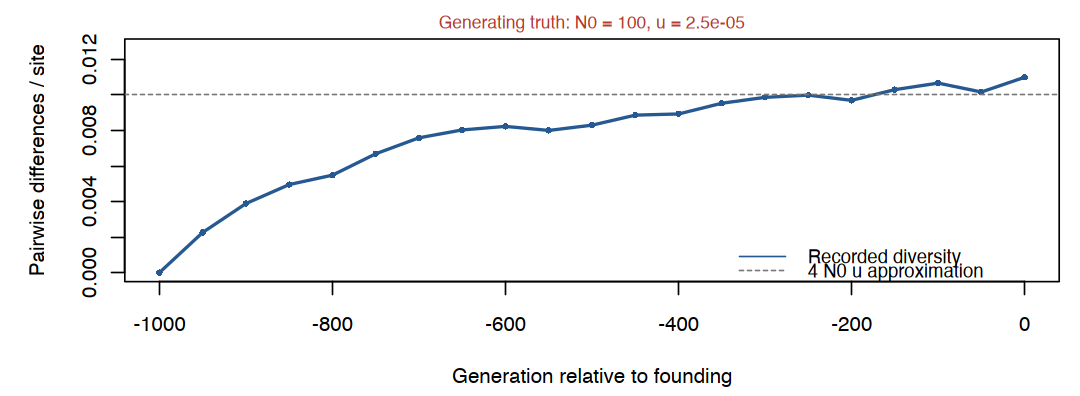

In [4]:
if (!is.null(simulation)) {
    drawFigure("population_burnin", function() {
        burn <- simulation$records$burnin
        H <- burn$heterozygosity * 2 * burn$size / (2 * burn$size - 1)
        par(mar = c(4.4, 4.8, 1.5, .8), bg = "white")
        plot(burn$generation, H, type = "o", pch = 16, cex = .55,
             col = blue, lwd = 2, xlab = "Generation relative to founding",
             ylab = "Pairwise differences / site", ylim = c(0, max(H) * 1.15))
        abline(h = 4 * population_design$ancestral_size *
            calibration$mutationRate, lty = 2, col = gray)
        legend("bottomright", c("Recorded diversity", "4 N0 u approximation"),
               lty = c(1, 2), col = c(blue, gray), bty = "n", cex = .9,
               y.intersp = 1.8)
        mtext(sprintf("Generating truth: N0 = %d, u = %.2g",
            population_design$ancestral_size, calibration$mutationRate),
            side = 3, line = .3, col = truth_color, cex = .85)
    }, height = 3.3)
}


The burn-in starts at zero diversity. The dashed line is the
low-mutation approximation $4N_0u=0.01$. A fluctuating trajectory is
one realization; a longer run is the appropriate check on burn-in.

The plots below use simulator records that a present-day study normally
cannot observe. The founder sample can change frequencies and remove
alleles immediately. Growth increases the number of descendants but does
not recreate the variants lost in that sample. New mutation supplies further
variation while drift and recombination continue.
The pre-founder and post-founder values are plotted at generation 0;
their vertical jump shows the instantaneous founder sample.


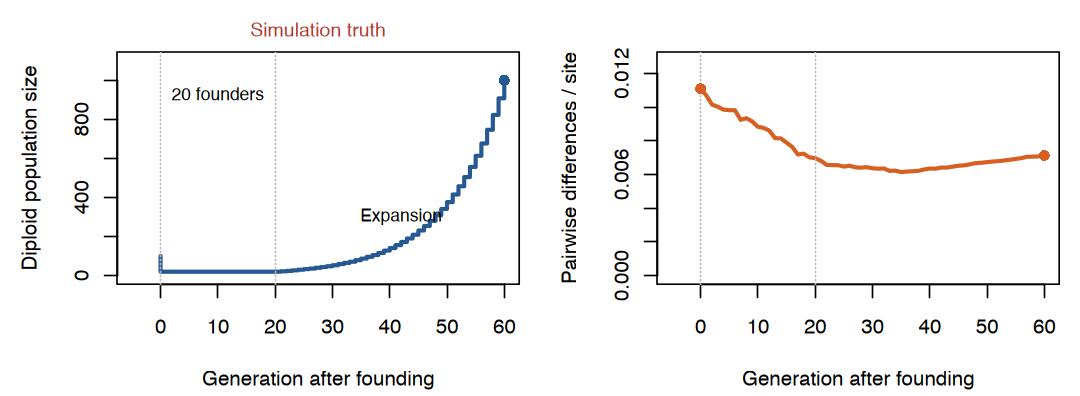

In [5]:
if (!is.null(simulation)) {
    drawFigure("population_demography", function() {
        record <- simulation$records$generation
        H <- record$heterozygosity * 2 * record$size / (2 * record$size - 1)
        ancestral <- tail(simulation$records$burnin, 1L)
        initial_H <- ancestral$heterozygosity * 2 * ancestral$size /
            (2 * ancestral$size - 1)
        time <- c(0, record$generation)
        par(mfrow = c(1, 2), mar = c(4.3, 4.5, 2, .8), bg = "white")
        plot(time, c(population_design$ancestral_size, record$size),
             type = "s", lwd = 2.5, xlim = c(-5, 60),
             col = blue, xlab = "Generation after founding",
             ylab = "Diploid population size", ylim = c(0, 1100))
        abline(v = c(0, 20), col = "#BBBBBB", lty = 3)
        mtext("Simulation truth", side = 3, line = .5,
              col = truth_color, cex = .95)
        text(10, 930, "20 founders", cex = .85)
        text(42, 300, "Expansion", cex = .85)
        points(60, 1000, pch = 16, col = blue)
        plot(time, c(initial_H, H), type = "l", col = orange, xlim = c(-5, 60),
             lwd = 2.5, xlab = "Generation after founding",
             ylab = "Pairwise differences / site",
             ylim = c(0, max(c(H, initial_H)) * 1.15))
        abline(v = c(0, 20), col = "#BBBBBB", lty = 3)
        points(record$generation[c(1, nrow(record))], H[c(1, length(H))],
               pch = 16, col = orange)
    }, height = 3.3)
}


## Analyze only the final DNA

From here onward the estimation functions use `observed`, `calibration`
and the candidate prediction banks. They do not receive `simulation`,
parental identities, recorded frequencies or the generating sizes.

The matrix displays the first 12 haplotypes at 12 common polymorphic sites
on chromosome 1. Labels give physical positions in bases. The complete
analysis uses all 16,000 sites and all 128 haplotypes.


 diploid_people haplotypes analyzed_sites segregating_sites pairwise_diversity
             64        128          16000               981          0.0071305


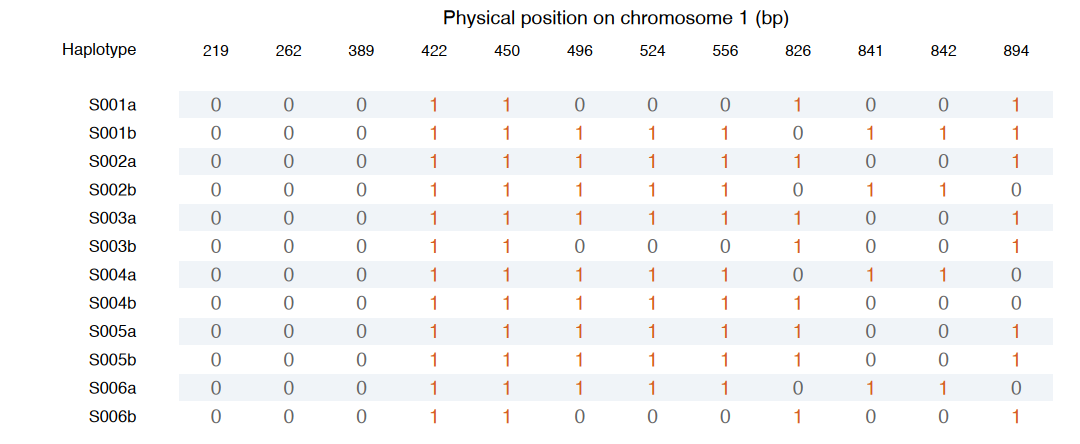

In [6]:
dna_summary <- summarizePopulationSample(observed$haplotypes,
    chromosome = observed$markers$chromosome)
print(data.frame(diploid_people = nrow(observed$genotypes),
    haplotypes = dna_summary$nHaplotypes, analyzed_sites = dna_summary$sequenceLength,
    segregating_sites = dna_summary$segregatingSites,
    pairwise_diversity = dna_summary$piPerSite), row.names = FALSE, digits = 5)

drawFigure("population_final_dna", function() {
    H <- observed$haplotypes
    frequency <- colMeans(H)
    sites <- which(observed$markers$chromosome == 1L &
                   pmin(frequency, 1 - frequency) >= .1)[1:12]
    subset <- H[1:12, sites, drop = FALSE]
    labels <- paste0(rep(observed$sample_ids[1:6], each = 2L), c("a", "b"))
    par(mar = c(.2, .2, .2, .2), bg = "white")
    plot(NA, xlim = c(-1.9, 12.8), ylim = c(-.8, 14.5),
         axes = FALSE, xlab = "", ylab = "", xaxs = "i", yaxs = "i")
    text(6.5, 14.0, "Physical position on chromosome 1 (bp)", cex = .95)
    text(1:12, 12.9, observed$markers$position[sites], cex = .75)
    text(-.1, 12.9, "Haplotype", adj = 1, cex = .8)
    for (i in 1:12) {
        y <- 12 - i
        rect(.5, y - .46, 12.5, y + .46,
             col = if (i %% 2L) "#F0F4F8" else "white", border = NA)
        text(-.1, y, labels[i], adj = 1, cex = .8)
        text(1:12, rep(y, 12), subset[i, ],
             col = ifelse(subset[i, ] == 1L, orange, "#666666"), cex = .95)
    }
}, height = 3.7)


Diversity counts differences between pairs of sequences. The folded SFS
counts sites at each minor allele count, from 1 through 64 among 128 copies.
The chromosomes differ because they have different realized copying and
recombination histories. They remain parts of the same sampled population.


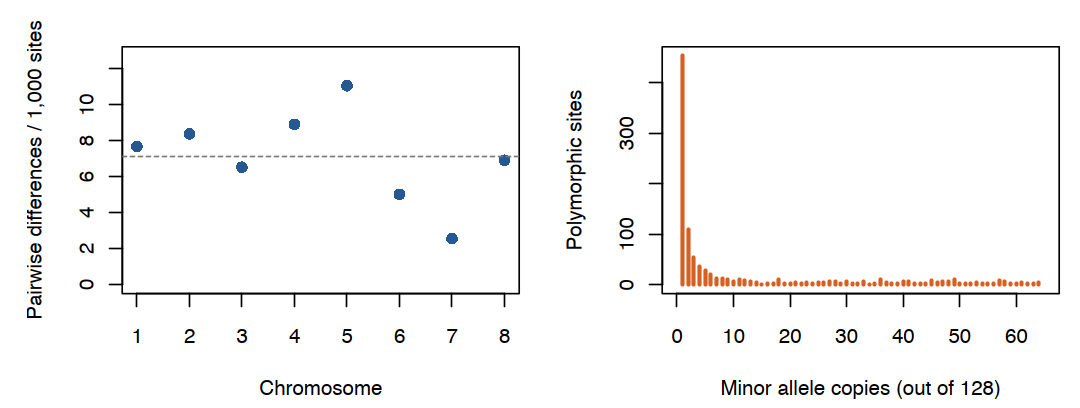

In [7]:
drawFigure("population_sample_summaries", function() {
    by_chr <- dna_summary$byChromosome
    H <- vapply(by_chr, `[[`, numeric(1), "piPerSite")
    par(mfrow = c(1, 2), mar = c(4.4, 4.7, 1.8, .8), bg = "white")
    plot(seq_along(H), 1000 * H, pch = 16, col = blue, cex = 1.1,
         xaxt = "n", xlab = "Chromosome", ylab = "Pairwise differences / 1,000 sites",
         ylim = c(0, max(H) * 1150))
    axis(1, seq_along(H), names(H))
    abline(h = 1000 * dna_summary$piPerSite, lty = 2, col = gray)
    plot(seq_along(dna_summary$foldedSfs), dna_summary$foldedSfs,
         type = "h", lwd = 2.5, col = orange,
         xlab = "Minor allele copies (out of 128)",
         ylab = "Polymorphic sites", xlim = c(0, 65))
}, height = 3.4)


## Estimate effective size using diversity and mutation rate

Apply the mutation-drift relation from Lecture 8 to the final DNA.
If $k_\ell$ of the $n=128$ sampled copies carry allele 1, then

$$\widehat\pi=\frac{1}{L}\sum_\ell
\frac{2k_\ell(n-k_\ell)}{n(n-1)},\qquad
\widehat N_{e,\pi}=\frac{\widehat\pi}{4u}.$$

Here $L=16{,}000$ includes invariant sites. The inverse assumes a neutral,
constant-size population and rare mutation. With changing population size,
it summarizes accumulated ancestral time; it need not equal today's census.


In [8]:
diversity_fit <- estimateDiversitySize(observed$haplotypes,
    mutationRate = calibration$mutationRate,
    sequenceLength = calibration$sequenceLength)
finite_state_fit <- estimateDiversitySize(observed$haplotypes,
    mutationRate = calibration$mutationRate,
    sequenceLength = calibration$sequenceLength,
    mutationModel = "symmetric_parental")
print(data.frame(pairwise_diversity = diversity_fit$piPerSite,
    mutation_rate = diversity_fit$mutationRate,
    Ne_rare_mutation = diversity_fit$Ne,
    Ne_symmetric_mutation = finite_state_fit$Ne), row.names = FALSE, digits = 6)


 pairwise_diversity mutation_rate Ne_rare_mutation Ne_symmetric_mutation
         0.00713049       2.5e-05          71.3049               72.8383


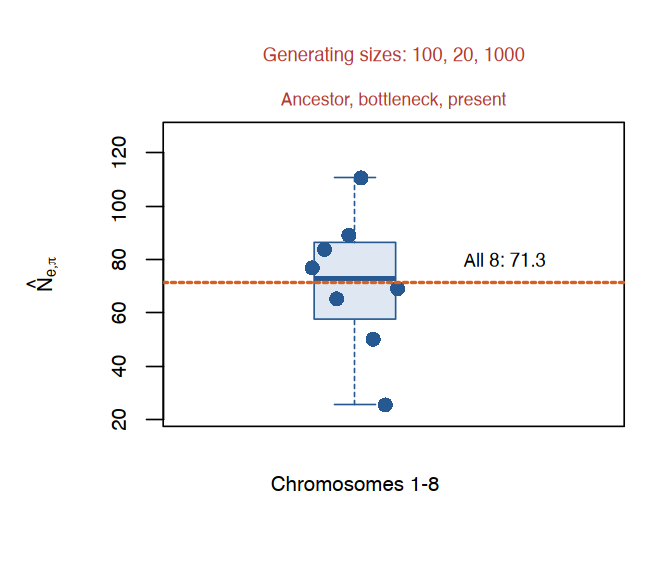

In [9]:
chromosome_sizes <- vapply(dna_summary$byChromosome,
    function(x) x$piPerSite / (4 * calibration$mutationRate), numeric(1))
drawFigure("population_diversity_estimates", function() {
    par(mar = c(4.4, 4.8, 3.6, .7), bg = "white")
    boxplot(chromosome_sizes, at = 1, boxwex = .42,
        xlim = c(.55, 1.65), ylim = range(chromosome_sizes) * c(.85, 1.15),
        col = "#DFE8F2", border = blue, outline = FALSE, xaxt = "n",
        ylab = expression(hat(N)[e*","*pi]), xlab = "")
    points(seq(.89, 1.11, length.out = length(chromosome_sizes)),
           chromosome_sizes, pch = 16, col = blue, cex = 1.1)
    axis(1, 1, "Chromosomes 1-8", tick = FALSE)
    abline(h = diversity_fit$Ne, col = orange, lty = 2, lwd = 2)
    text(1.28, diversity_fit$Ne + 6,
        sprintf("All 8: %.1f", diversity_fit$Ne), adj = c(0, 0), cex = .9)
    mtext(sprintf("Generating sizes: %d, %d, %d",
        population_design$ancestral_size,
        candidate_designs$recent_founding$small,
        population_design$present_size), side = 3, line = 1.7,
        col = truth_color, cex = .9)
    mtext("Ancestor, bottleneck, present", side = 3, line = .4,
          col = truth_color, cex = .85)
}, width = 5.4, height = 4.8, pointsize = 17)


The simulation uses finite biallelic sites. The second estimate
applies the corresponding symmetric-mutation equilibrium correction.
Diversity gives about 71.3 with the rare-mutation relation and 72.8 with
that correction. This small difference checks the approximation; neither
calculation reconstructs a time-varying size history.

Each point and the box summarize the eight chromosome-specific estimates
within this one sample. They are not replicate estimates from independent
populations or a confidence interval for the pooled estimate. Red labels
give the generating size history, which is withheld from estimation.


## Estimate effective size using LD and recombination

Use one fixed homolog from each of the same 64 people, giving $n=64$
known-phase haplotypes. Keep sites with sample minor allele frequency at
least 0.1. The map converts distance $d$ to $r=(1-e^{-2d})/2$.

Apply the weak-LD equilibrium relation from Lecture 8,

$$E(\rho_{AB}^2)\approx\frac{\gamma(r)}{N_e},\qquad
\gamma(r)=\frac{(1-r)^2+r^2}{2r(2-r)}.$$

The leading sampling contribution is approximately $1/n$.
With different map distances, pool the factors as well as the observations,

$$\widehat N_{e,\mathrm{LD}}\approx
\frac{\overline{\gamma(r)}}{\overline{\widehat\rho_{AB}^{\,2}}-1/n}.$$

We use distances 0.03-0.20 Morgans. Tighter pairs can violate the weak-LD
approximation. The sampling correction is approximate for this finite,
paired-diploid population sample. Population simulations below retain the
same sampling design when calibrating predictions.


 lowerMorgan upperMorgan pairs  meanRho2 correctedRho2      Ne
        0.03        0.07   895 0.0386159    0.02299093 228.476
        0.07        0.12   823 0.0218191    0.00619415 423.592
        0.12        0.20   449 0.0184256    0.00280063 595.913


Pooled LD estimate: 282.56 


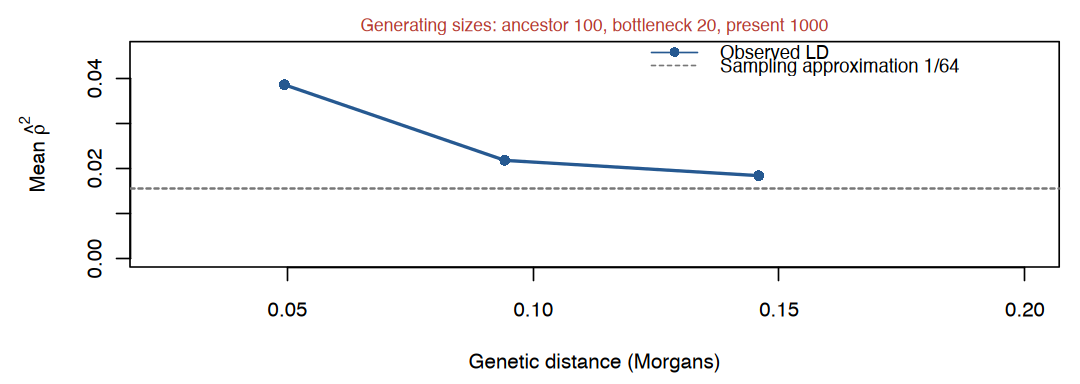

In [10]:
ld_haplotypes <- observed$haplotypes[
    seq(1L, nrow(observed$haplotypes), 2L), , drop = FALSE]
ld_fit <- estimateLdSize(ld_haplotypes,
    geneticPositions = observed$markers$genetic_position,
    chromosome = observed$markers$chromosome,
    distanceBreaks = population_design$ld_distance_breaks,
    maxPairs = 500000L, seed = 101L)
print(ld_fit$bins[c("lowerMorgan", "upperMorgan", "pairs", "meanRho2",
                   "correctedRho2", "Ne")], row.names = FALSE, digits = 6)
cat("Pooled LD estimate:", round(ld_fit$Ne, 2), "\n")

drawFigure("population_ld_estimates", function() {
    bins <- ld_fit$bins
    par(mar = c(4.5, 5, 1.6, .8), bg = "white")
    plot(bins$meanDistance, bins$meanRho2, type = "o", pch = 16,
         col = blue, lwd = 2, xlim = c(.025, .2),
         ylim = c(0, max(bins$meanRho2) * 1.2),
         xlab = "Genetic distance (Morgans)",
         ylab = expression("Mean " * hat(rho)^2))
    abline(h = ld_fit$samplingCorrection, lty = 2, col = gray, lwd = 1.5)
    legend("topright", c("Observed LD", "Sampling approximation 1/64"),
           col = c(blue, gray), lty = c(1, 2), pch = c(16, NA),
           bty = "n", cex = .9, y.intersp = 1.8)
    mtext(sprintf("Generating sizes: ancestor %d, bottleneck %d, present %d",
        population_design$ancestral_size,
        candidate_designs$recent_founding$small, population_design$present_size),
          side = 3, line = .3, col = truth_color, cex = .85)
}, height = 3.2)


The pooled LD estimate is about 283. The three distance-bin inverses are
about 228, 424 and 596. Each applies a constant-size approximation to one
range of genetic distances. These are not estimates for three separate
historical epochs. Linked pairs share sites and chromosomes, so their count
is not an independent replicate count.


             quantity estimate
 Diversity + mutation  71.3049
             LD + map 282.5638


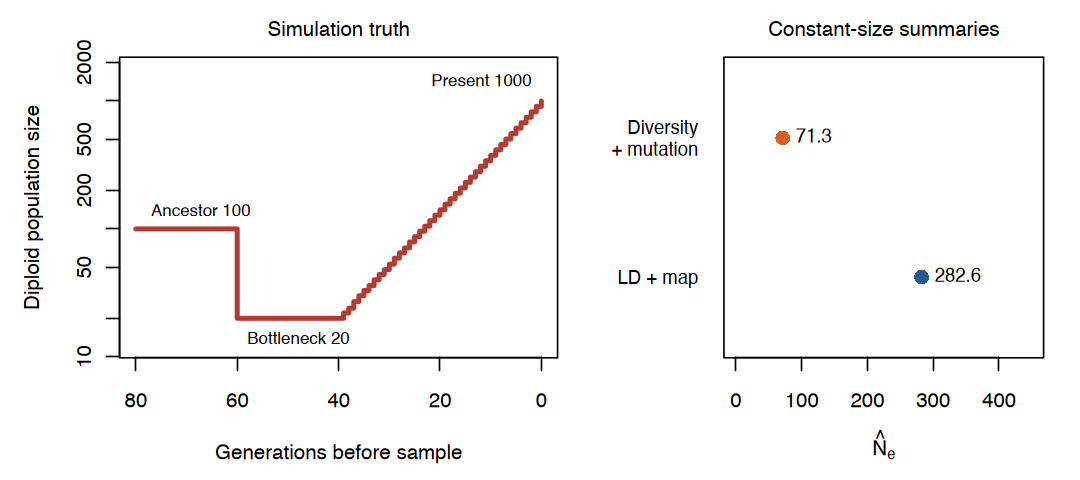

In [11]:
print(data.frame(quantity = c("Diversity + mutation", "LD + map"),
    estimate = c(diversity_fit$Ne, ld_fit$Ne)), row.names = FALSE, digits = 6)
drawFigure("population_ne_comparison", function() {
    layout(matrix(1:2, nrow = 1), widths = c(1.12, 1))
    par(mar = c(4.7, 4.6, 2.2, .5), bg = "white")
    candidate <- candidate_designs$recent_founding
    schedule <- populationSizeSchedule(candidate, population_design)
    schedule[1L] <- candidate$founder
    age <- rev(seq_along(schedule) - 1L)
    plot(c(80, 60.01, age), c(population_design$ancestral_size,
        population_design$ancestral_size, schedule), type = "s", log = "y",
        xlim = c(80, 0), ylim = c(12, 1800), col = truth_color, lwd = 3,
        xlab = "Generations before sample", ylab = "Diploid population size",
        main = "Simulation truth", cex.main = 1)
    text(77, 140, paste("Ancestor", population_design$ancestral_size),
         adj = 0, cex = .82)
    text(58, 14, paste("Bottleneck", candidate$small), adj = 0, cex = .82)
    text(2, 1450, paste("Present", population_design$present_size),
         adj = 1, cex = .82)
    values <- c(diversity_fit$Ne, ld_fit$Ne)
    par(mar = c(4.7, 5.9, 2.2, 1.4))
    plot(values, 2:1, pch = 16, col = c(orange, blue), cex = 1.4,
         yaxt = "n", xlim = c(0, 450), ylim = c(.5, 2.5),
         xlab = expression(hat(N)[e]), ylab = "",
         main = "Constant-size summaries", cex.main = 1)
    axis(2, 2:1, c("Diversity\n+ mutation", "LD + map"),
         las = 1, tick = FALSE, cex.axis = .9)
    text(values, 2:1, labels = round(values, 1), pos = 4, cex = .9)
}, height = 4)


These estimates use the same final DNA. Diversity combines mutation with
long ancestral paths. LD combines drift with recombination and has a
different sensitivity to the past. The present census of 1,000 is known
here because we generated the population; it is not supplied to either estimator.

A single constant-size summary cannot specify when a bottleneck occurred
or how long it lasted. We now compare complete histories by their predicted
final-sample patterns.


## Compare explicit population histories

All candidates begin at 100, end at 1,000, and use the same mutation rate,
map, sequence length and sampling design. They differ in the founder
sample and subsequent size trajectory. The older-founding candidate also
expands more slowly because its growth phase lasts 80 generations.

These are competing hypotheses for one sample, not additional example
populations. We compare which declared trajectory predicts the sample best;
the comparison does not estimate arbitrary founder numbers or dates.


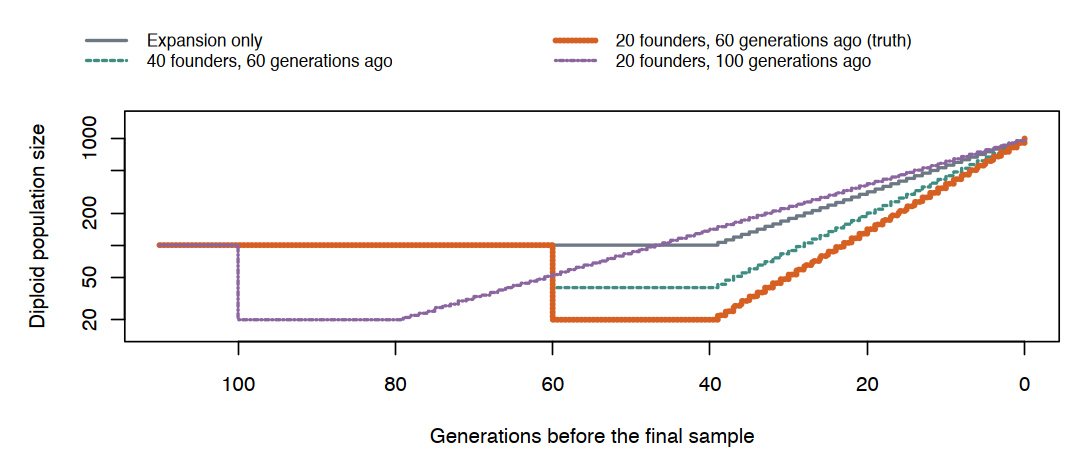

In [12]:
drawFigure("population_candidate_histories", function() {
    layout(matrix(1:2, ncol = 1L), heights = c(.85, 3))
    par(mar = rep(0, 4), bg = "white")
    plot.new()
    validation_labels <- candidate_labels
    validation_labels["recent_founding"] <- paste0(
        validation_labels["recent_founding"], " (truth)")
    legend("center", validation_labels, col = model_colors,
           lty = seq_along(candidate_designs), lwd = c(2, 2, 3.5, 2), bty = "n", cex = .83,
           y.intersp = 1.8, ncol = 2)
    par(mar = c(4.4, 4.8, .4, .8))
    plot(NA, xlim = c(110, 0), ylim = c(15, 1500), log = "y",
         xlab = "Generations before the final sample", ylab = "Diploid population size")
    for (i in seq_along(candidate_designs)) {
        candidate <- candidate_designs[[i]]
        schedule <- populationSizeSchedule(candidate, population_design)
        age <- rev(seq_along(schedule) - 1L)
        schedule[1L] <- if (is.null(candidate$founder)) 100L else candidate$founder
        lines(c(110, age[1] + .01, age), c(100, 100, schedule),
              type = "s", lwd = if (names(candidate_designs)[i] ==
                  "recent_founding") 3.5 else 2, col = model_colors[i], lty = i)
    }
}, height = 3.8)


Fit with chromosomes 1–6 and reserve chromosomes 7–8 for a predictive check.
For each candidate, 12 R simulation replicates fix the mean predictions
and variance scales; 20 separate replicates calibrate the discrepancy.
All 128 seeds are fixed and disjoint from the observation seed.

The summaries are three folded-SFS groups and three raw LD distance bins.
Squared residuals are divided by common simulation variances and added.
Whole-population calibration replicates preserve the correlations among
summaries and chromosomes. The discrepancy measures fit to the specified
candidate histories.


In [13]:
fit_features <- populationSampleFeatures(observed, population_design, population_design$fitting_chromosomes)
check_features <- populationSampleFeatures(observed, population_design, population_design$checking_chromosomes)
banks <- prediction_data$banks
history_library <- buildHistoryLibrary(
    training = lapply(banks, `[[`, "train_fit"),
    calibration = lapply(banks, `[[`, "cal_fit"))
heldout_library <- buildHistoryLibrary(
    training = lapply(banks, `[[`, "train_check"),
    calibration = lapply(banks, `[[`, "cal_check"))
history_fit <- comparePopulationHistories(fit_features, history_library)
history_check <- comparePopulationHistories(check_features, heldout_library)


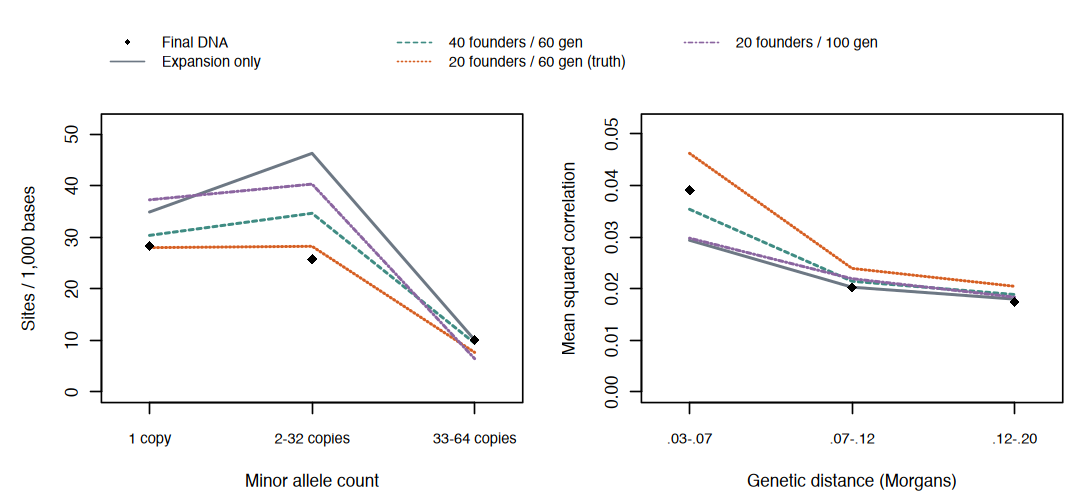

In [14]:
drawFigure("population_history_predictions", function() {
    layout(matrix(c(1, 1, 2, 3), nrow = 2L, byrow = TRUE), heights = c(.85, 3.3))
    par(mar = rep(0, 4), bg = "white")
    plot.new()
    legend("center", c("Final DNA", "Expansion only", "40 founders / 60 gen",
        "20 founders / 60 gen (truth)", "20 founders / 100 gen"),
        col = c("black", model_colors), lty = c(NA, 1:4),
        pch = c(18, rep(NA, 4)), bty = "n", cex = .85, ncol = 3,
        y.intersp = 1.8)
    par(mar = c(4.7, 4.7, .5, .8))
    predicted <- history_library$centers
    groups <- list(1:3, 4:6)
    labels <- list(c("1 copy", "2-32 copies", "33-64 copies"),
                   c(".03-.07", ".07-.12", ".12-.20"))
    for (panel in 1:2) {
        index <- groups[[panel]]
        factor <- if (panel == 1) 1000 else 1
        values <- predicted[, index, drop = FALSE] * factor
        observed_values <- fit_features[index] * factor
        plot(NA, xlim = c(.8, 3.2),
             ylim = range(c(0, values, observed_values)) * c(1, 1.12),
             xaxt = "n", xlab = if (panel == 1) "Minor allele count" else
                 "Genetic distance (Morgans)",
             ylab = if (panel == 1) "Sites / 1,000 bases" else "Mean squared correlation")
        axis(1, 1:3, labels[[panel]], cex.axis = .85)
        for (i in 1:4) lines(1:3, values[i, ], lwd = 1.8,
            col = model_colors[i], lty = i)
        points(1:3, observed_values, pch = 18, cex = 1.25)
    }
}, height = 4.2)


        candidate discrepancy compatibility
  recent_founding     7.56109     0.4285714
 shallow_founding    20.80516     0.0952381
   older_founding    91.38293     0.0476190
   expansion_only   117.02666     0.0476190


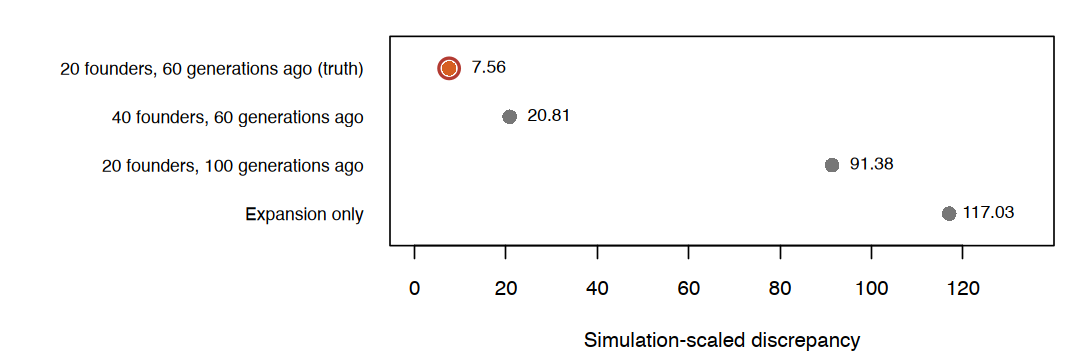

In [15]:
print(history_fit$profile, row.names = FALSE, digits = 6)
drawFigure("population_history_fit", function() {
    profile <- history_fit$profile
    validation_labels <- candidate_labels[profile$candidate]
    is_truth <- profile$candidate == "recent_founding"
    validation_labels[is_truth] <- paste0(validation_labels[is_truth], " (truth)")
    par(mar = c(4.4, 15, 1.4, 1), bg = "white")
    y <- rev(seq_len(nrow(profile)))
    plot(profile$discrepancy, y, pch = 16,
         col = c(orange, rep(gray, nrow(profile) - 1L)), cex = 1.4,
         yaxt = "n", ylim = c(.5, 4.5),
         xlim = c(0, max(profile$discrepancy) * 1.15),
         xlab = "Simulation-scaled discrepancy", ylab = "")
    axis(2, y, validation_labels, las = 1, tick = FALSE,
         cex.axis = .85)
    points(profile$discrepancy[is_truth], y[is_truth], pch = 1,
           col = truth_color, cex = 2, lwd = 2)
    text(profile$discrepancy, y, format(round(profile$discrepancy, 2), nsmall = 2),
         pos = 4, cex = .85)
}, height = 3.0)


The smallest discrepancy identifies the closest candidate among the
four specified trajectories. The simulation check fraction is the fraction
of independent calibration samples at least as discrepant as the observed
DNA, with one added to both the numerator and denominator.

With 20 calibration replicates, its resolution is $1/21$. Interpret the
selected trajectory together with the reserved-chromosome prediction check.


       candidate discrepancy compatibility
 recent_founding     19.0936      0.142857


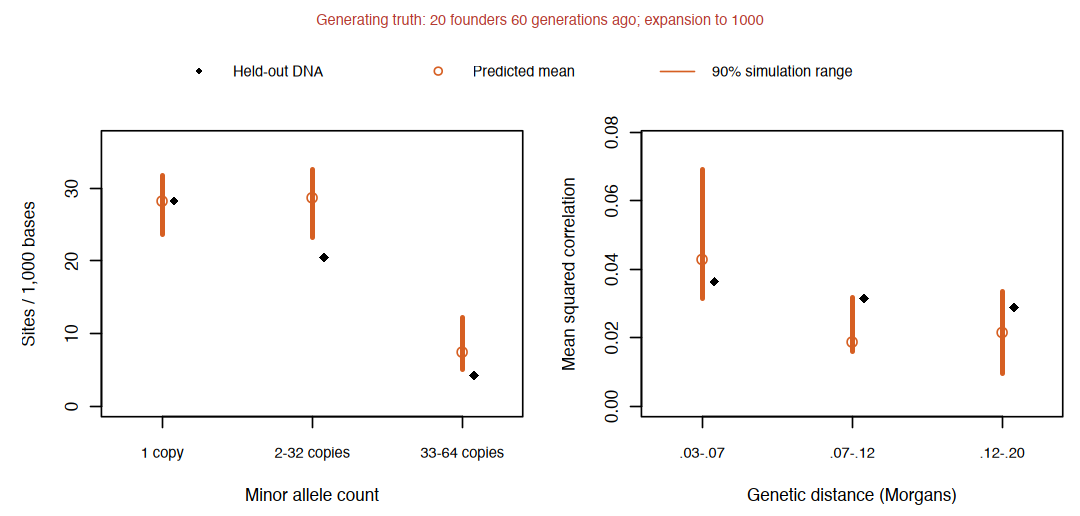

In [16]:
selected_history <- history_fit$selected
selected_check <- history_check$profile[
    history_check$profile$candidate == selected_history, , drop = FALSE]
print(selected_check, row.names = FALSE, digits = 6)
heldout_draws <- heldout_library$calibration[[selected_history]]
heldout_range <- apply(heldout_draws, 2L, quantile, c(.05, .95))

drawFigure("population_history_check", function() {
    layout(matrix(c(1, 1, 2, 3), nrow = 2L, byrow = TRUE), heights = c(1, 3.3))
    par(mar = rep(0, 4), bg = "white")
    plot.new()
    text(.5, .85, sprintf(
        "Generating truth: %d founders %d generations ago; expansion to %d",
        candidate_designs$recent_founding$founder,
        candidate_designs$recent_founding$duration +
            candidate_designs$recent_founding$growth,
        population_design$present_size), col = truth_color, cex = .85)
    legend(.5, .4, c("Held-out DNA", "Predicted mean", "90% simulation range"),
        pch = c(18, 1, NA), lty = c(NA, NA, 1),
        col = c("black", orange, orange), bty = "n", cex = .85, ncol = 3,
        xjust = .5, yjust = .5)
    par(mar = c(4.6, 4.7, .5, .8))
    labels <- list(c("1 copy", "2-32 copies", "33-64 copies"),
                   c(".03-.07", ".07-.12", ".12-.20"))
    for (panel in 1:2) {
        index <- if (panel == 1) 1:3 else 4:6
        factor <- if (panel == 1) 1000 else 1
        center <- heldout_library$centers[selected_history, index] * factor
        interval <- heldout_range[, index, drop = FALSE] * factor
        observed_values <- check_features[index] * factor
        plot(NA, xlim = c(.7, 3.3),
             ylim = range(c(0, interval, observed_values)) * c(1, 1.12),
             xaxt = "n", xlab = if (panel == 1) "Minor allele count" else
                 "Genetic distance (Morgans)",
             ylab = if (panel == 1) "Sites / 1,000 bases" else "Mean squared correlation")
        axis(1, 1:3, labels[[panel]], cex.axis = .85)
        segments(1:3, interval[1, ], 1:3, interval[2, ], col = orange, lwd = 3)
        points(1:3, center, pch = 1, col = orange, cex = 1.1)
        points((1:3) + .08, observed_values, pch = 18, cex = 1.2)
    }
}, height = 4.3)


Compare the selected candidate's held-out discrepancy and calibration
fraction with its training fit. The prediction ranges show which folded-SFS
or LD summaries are unusual under that history.

Chromosomes share a pedigree, so the whole-dataset check retains their
dependence. More chromosomes, finer candidate grids and richer demographic
models address different sources of uncertainty.


## Read the final sample's results together

Diversity and LD summarize different parts of the population history.
The candidate comparison evaluates a complete size trajectory using the same DNA.
The left panel shows the two size estimates and the generating census.
The right panel shows the history comparison and its held-out check.
Red symbols identify simulation truth.


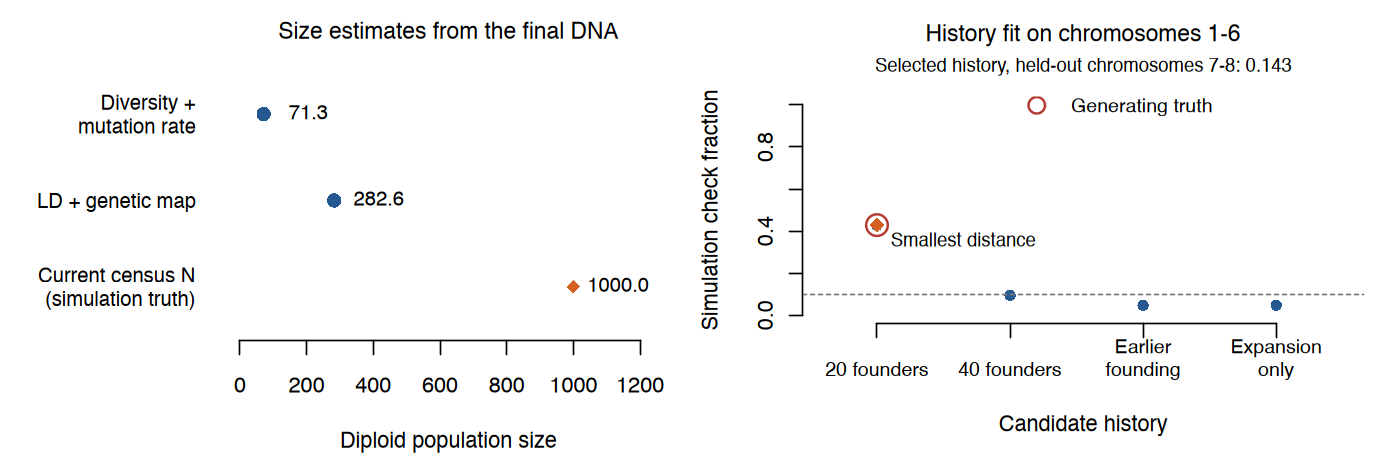

In [17]:
comparison_validation <- list(
    diversity_estimate = unname(diversity_fit$Ne),
    finite_state_estimate = unname(finite_state_fit$Ne),
    ld_estimate = unname(ld_fit$Ne),
    current_census = population_design$present_size,
    selected_history = history_fit$selected,
    heldout_check = unname(selected_check$compatibility))

package_result <- populationHistoryExample(observed, calibration, prediction_data)
stopifnot(identical(diversity_fit, package_result$diversity_fit),
          identical(finite_state_fit, package_result$finite_state_fit),
          identical(ld_fit, package_result$ld_fit),
          identical(history_fit, package_result$history_fit),
          identical(history_check, package_result$history_check))

drawFigure("p7_common_sample_validation", function() {
    par(mfrow = c(1, 2), bg = "white", cex = 1.06, cex.main = 1.05)
    par(mar = c(4.2, 8.1, 2.2, .6))
    values <- c(comparison_validation$diversity_estimate,
                comparison_validation$ld_estimate,
                comparison_validation$current_census)
    plot(NA, xlim = c(0, max(values) * 1.25), ylim = c(.5, 3.5), yaxt = "n",
         xlab = "Diploid population size", ylab = "", bty = "n",
         main = "Size estimates from the final DNA")
    axis(2, 3:1, c("Diversity +\nmutation rate", "LD + genetic map",
         "Current census N\n(simulation truth)"),
         las = 1, tick = FALSE, cex.axis = .93)
    points(values, 3:1, pch = c(16, 16, 18), col = c(blue, blue, orange), cex = 1.3)
    text(values, 3:1, format(round(values, 1), nsmall = 1), pos = 4, cex = .93)

    par(mar = c(4.8, 4.1, 3.5, .6))
    profile <- history_fit$profile
    best <- match(history_fit$selected, profile$candidate)
    truth <- match("recent_founding", profile$candidate)
    plot(seq_len(nrow(profile)), profile$compatibility, pch = 16,
         col = blue, xlim = c(.6, 4.5), ylim = c(0, 1), xaxt = "n", bty = "n",
         xlab = "Candidate history", ylab = "Simulation check fraction")
    title(main = "History fit on chromosomes 1-6", line = 2)
    labels <- c(expansion_only = "Expansion\nonly", shallow_founding = "40 founders",
        recent_founding = "20 founders", older_founding = "Earlier\nfounding")
    axis(1, seq_len(nrow(profile)), labels[profile$candidate], cex.axis = .9)
    abline(h = .1, lty = 2, col = gray)
    points(best, profile$compatibility[best], pch = 18, col = orange, cex = 1.5)
    points(truth, profile$compatibility[truth], pch = 1, col = truth_color,
           cex = 2, lwd = 1.5)
    text(best, profile$compatibility[best] - .08, "Smallest distance", pos = 4, cex = .85)
    mtext(sprintf("Selected history, held-out chromosomes 7-8: %.3f",
                  comparison_validation$heldout_check), side = 3, line = .8, cex = .9)
    legend("topright", "Generating truth", pch = 1, col = truth_color,
           pt.cex = 1.5, pt.lwd = 1.5, bty = "n", cex = .9)
}, width = 11.5, height = 3.8)


## Rebuild the cache

The observations and all prediction/calibration replicates use hpgR's R
functions with the recorded design and seeds. From the package source:

```r
system2("Rscript", c("tools/rebuild_population_cache.R", "/path/to/cache", "4"))
```

The generated RDS files contain the inputs embedded in this notebook.


## Sources

[Pritchard, Sections 2.1–2.3](https://web.stanford.edu/group/pritchardlab/HGBook.html);
Peng et al. (2012), *Forward-Time Population Genetics Simulations*;
Hill (1981), *Genetical Research* 38, 209–216;
*Handbook of Statistical Genomics*, Section 16.2.2.

Simulation and inference functions are documented in hpgR.
